<a href="https://colab.research.google.com/github/M0-G/CS488/blob/CS-488-DEMO/CS488_Final_Project_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Load data and split

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)

# In Colab, upload heart_statlog.csv when prompted (skipped if the file is already here)
if not os.path.exists("heart_statlog.csv"):
    from google.colab import files
    print("Please upload heart_statlog.csv")
    files.upload()

df = pd.read_csv("heart_statlog.csv")
print("Shape:", df.shape)
df.head()

Shape: (1190, 12)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [ ]:
# Remove duplicate rows BEFORE splitting, so copies can't leak from train into test
print("Rows before:", len(df), "| duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

# Impossible zeros (cholesterol and resting blood pressure cannot be 0)
for col in ["cholesterol", "resting bp s"]:
    print(f"Zeros in '{col}':", (df[col] == 0).sum())

# 2. Stratified 80/20 split (same seed for every model)
x_axis, y_axis = df.drop(columns="target"), df["target"]
x_train, x_test, y_train, y_test = train_test_split(
    x_axis, y_axis, test_size=0.2, stratify=y_axis, random_state=42
)
x_train, x_test = x_train.copy(), x_test.copy()

# 3. Treat impossible zeros as missing and fill with the TRAIN median (no test leakage)
for col in ["cholesterol", "resting bp s"]:
    x_train[col] = x_train[col].replace(0, np.nan)
    x_test[col] = x_test[col].replace(0, np.nan)
    median = x_train[col].median()
    x_train[col] = x_train[col].fillna(median)
    x_test[col] = x_test[col].fillna(median)

print("\nTrain/test sizes:", len(x_train), len(x_test))

Rows before: 1190 | duplicate rows: 272
Rows after removing duplicates: 918
Zeros in 'cholesterol': 172
Zeros in 'resting bp s': 1

Train/test sizes: 734 184


##Training Data Analysis

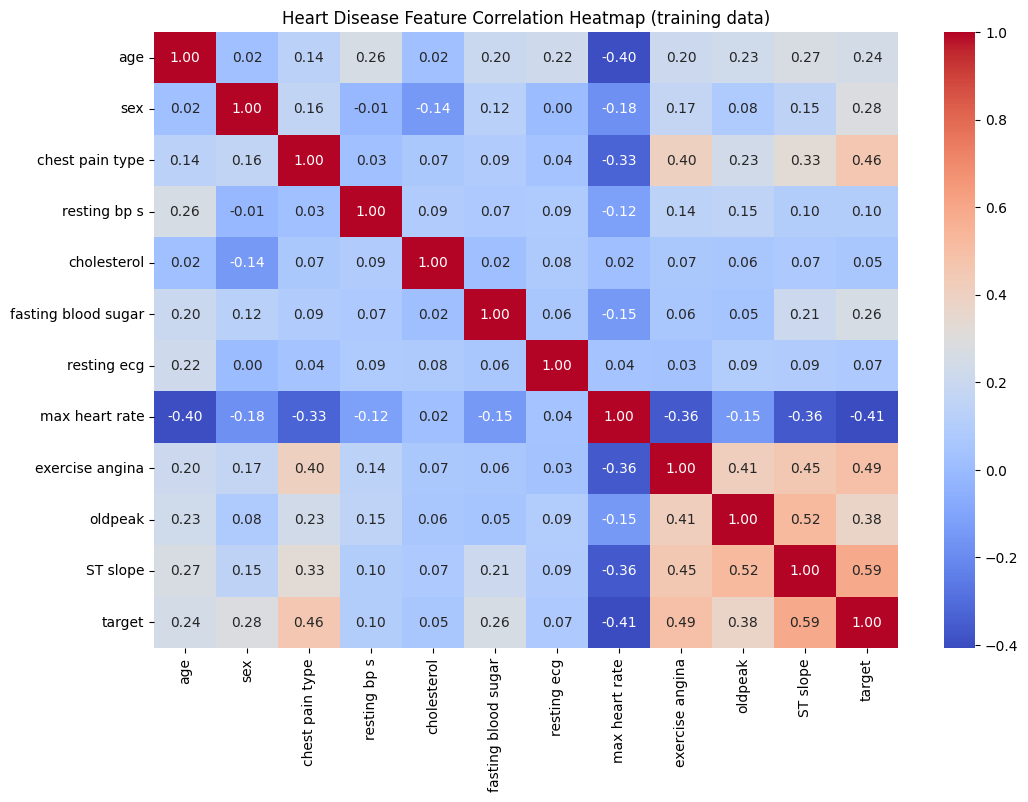

In [ ]:
train_df = x_train.copy()
train_df["target"] = y_train.values

plt.figure(figsize=(12, 8))
sns.heatmap(
    train_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Heart Disease Feature Correlation Heatmap")
plt.show()

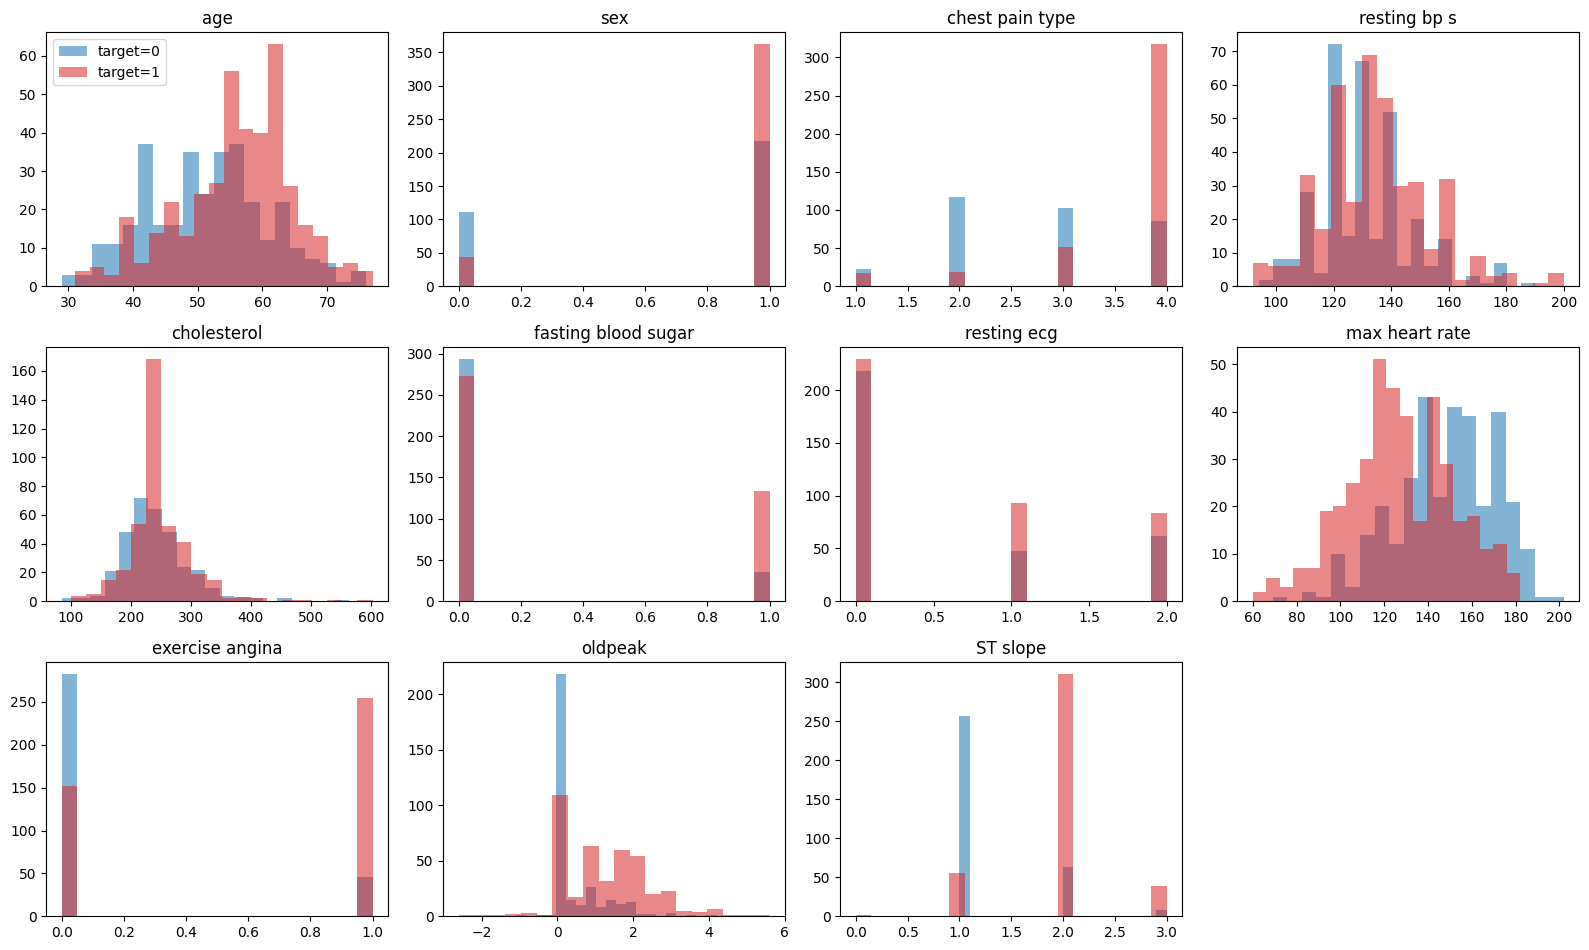

In [ ]:
# Histogram of every feature. blue = no disease, red = disease.
cols = list(x_train.columns)
n_cols = 4
n_rows = int(np.ceil(len(cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))

for ax, c in zip(axes.ravel(), cols):
    for label, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(train_df.loc[train_df["target"] == label, c], bins=20, alpha=0.55,
                color=color, label=f"target={label}")
    ax.set_title(c)

for ax in axes.ravel()[len(cols):]:
    ax.axis("off")

axes.ravel()[0].legend()
plt.tight_layout()
plt.show()

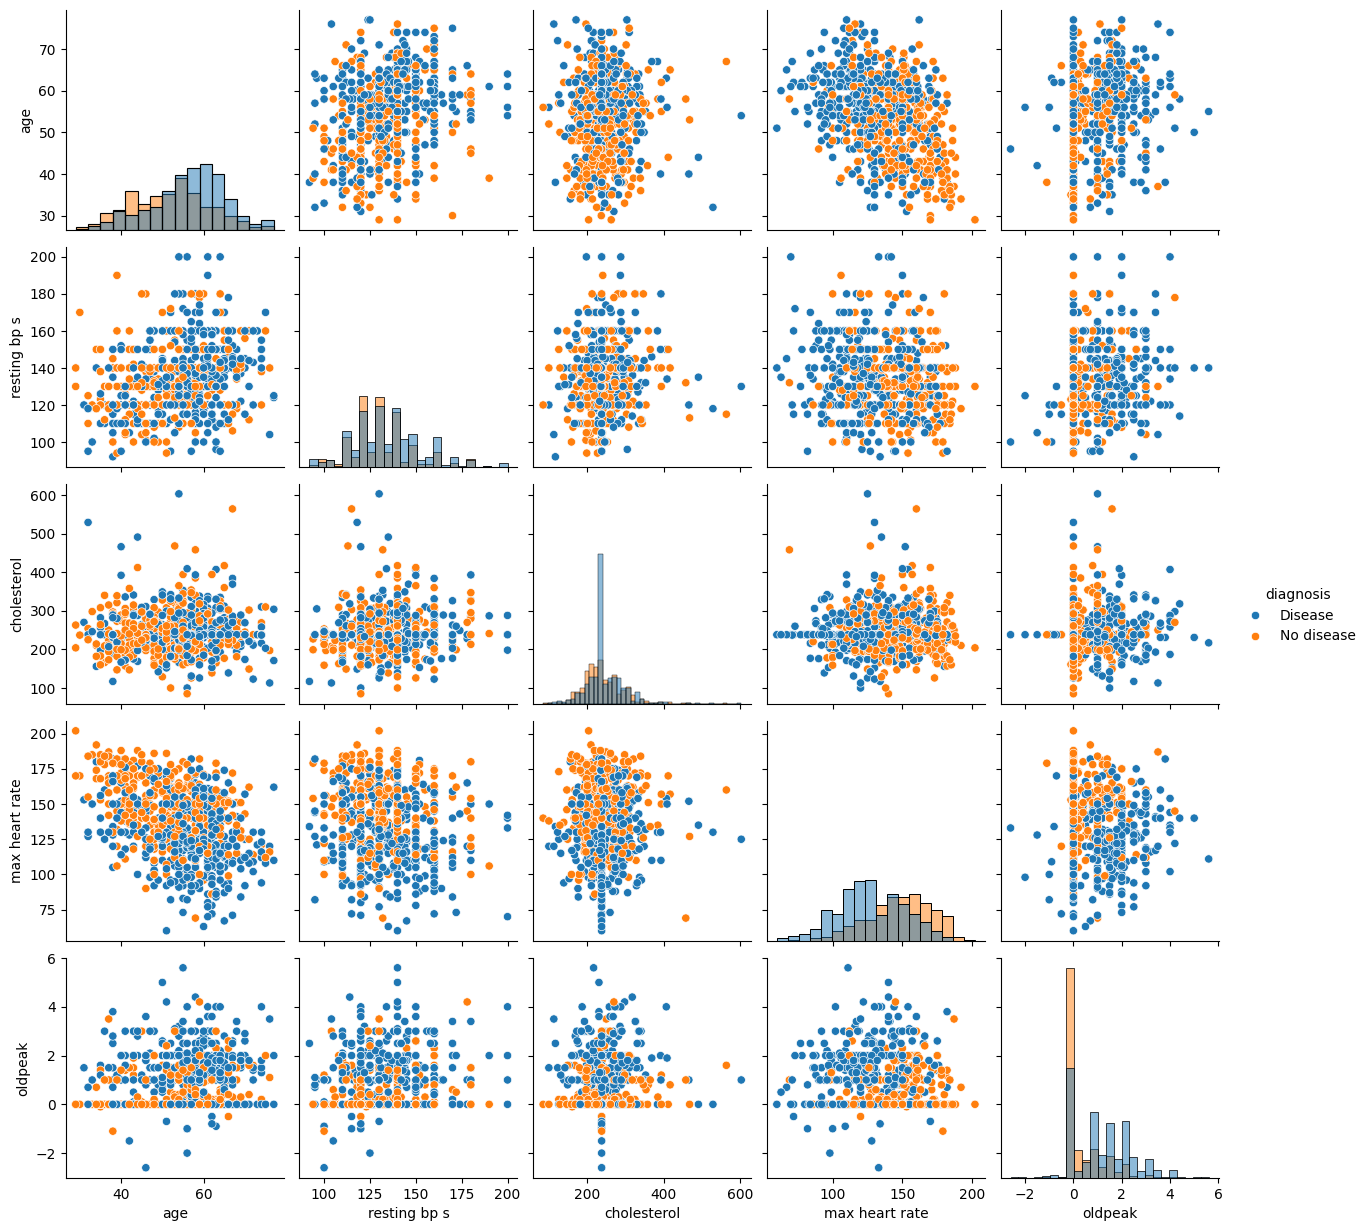

In [ ]:
# Pair plot of the continuous features
continuous_cols = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
pair_df = x_train[continuous_cols].copy()
pair_df["diagnosis"] = y_train.map({0: "No disease", 1: "Disease"}).values

sns.pairplot(pair_df, hue="diagnosis", diag_kind="hist")
plt.show()

##PCA & Feature Selection

Feature ranking:
                     abs_corr  mutual_info  rf_importance  avg_rank
ST slope                0.588        0.237          0.251     1.000
chest pain type         0.461        0.153          0.127     2.333
exercise angina         0.491        0.123          0.075     4.000
max heart rate          0.407        0.077          0.121     4.000
oldpeak                 0.377        0.089          0.107     4.333
age                     0.245        0.057          0.082     6.667
cholesterol             0.055        0.063          0.082     7.667
sex                     0.280        0.032          0.035     7.667
fasting blood sugar     0.261        0.013          0.028     9.000
resting bp s            0.102        0.010          0.069     9.333
resting ecg             0.074        0.020          0.024    10.000


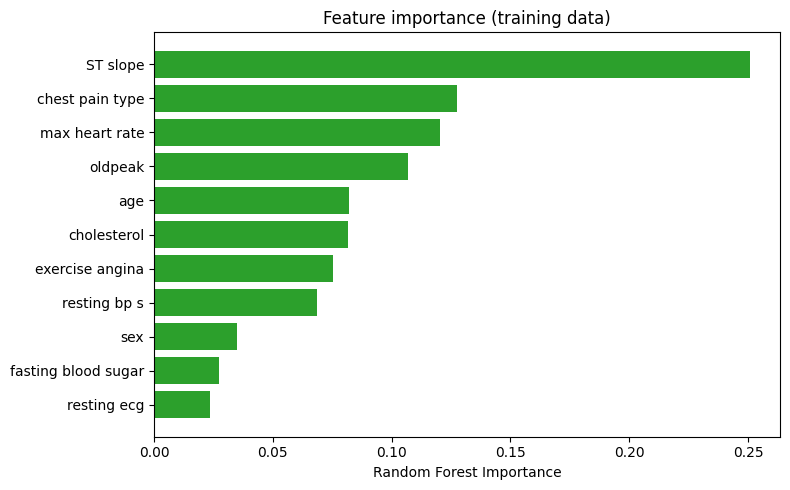

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def rank_features(X_tr, y_tr):
    corr = X_tr.corrwith(y_tr).abs()                                   # linear link to target
    mi = pd.Series(mutual_info_classif(X_tr, y_tr, random_state=42),   # any dependence on target
                   index=X_tr.columns)
    rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    rf_imp = pd.Series(rf.feature_importances_, index=X_tr.columns)    # tree importance

    table = pd.DataFrame({"abs_corr": corr, "mutual_info": mi, "rf_importance": rf_imp})
    # Rank 1 = best. Lowest average rank = most useful feature
    table["avg_rank"] = table.rank(ascending=False).mean(axis=1)
    return table.sort_values("avg_rank")

ranking = rank_features(x_train, y_train)
print("Feature ranking:")
print(ranking.round(3))

t = ranking.sort_values("rf_importance")
plt.figure(figsize=(8, 5))
plt.barh(t.index, t["rf_importance"], color="tab:green")
plt.xlabel("Random Forest Importance")
plt.title("Feature importance (training data)")
plt.tight_layout()
plt.show()

In [ ]:
def select_features(X_tr, y_tr, X_te, k=8, corr_threshold=0.85):
    # Remove highly correlated duplicates
    corr = X_tr.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    drop = [c for c in upper.columns if (upper[c] > corr_threshold).any()]
    print("Dropped for high correlation:", drop)
    X_tr2 = X_tr.drop(columns=drop)

    # Rank and keep the top k
    table = rank_features(X_tr2, y_tr)
    selected = list(table.index[:k])

    # Same columns applied to test so train and test match
    return X_tr[selected], X_te[selected], selected

x_train_sel, x_test_sel, selected_cols = select_features(x_train, y_train, x_test)
print("Selected features:", selected_cols)

Dropped for high correlation: []
Selected features: ['ST slope', 'chest pain type', 'exercise angina', 'max heart rate', 'oldpeak', 'age', 'cholesterol', 'sex']


PCA components kept: 10 of 11


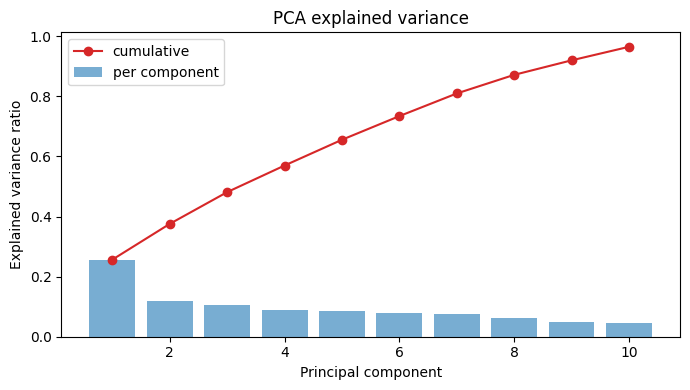

In [ ]:
# Scale, then PCA keeping 95% of the variance. Fit on train only, then applied to test.
scaler = StandardScaler().fit(x_train)
pca = PCA(n_components=0.95, random_state=42)
x_train_pca = pca.fit_transform(scaler.transform(x_train))
x_test_pca = pca.transform(scaler.transform(x_test))
print("PCA components kept:", x_train_pca.shape[1], "of", x_train.shape[1])

cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, alpha=0.6, label="per component")
plt.plot(range(1, len(cum) + 1), cum, "o-", color="tab:red", label="cumulative")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA explained variance")
plt.legend()
plt.tight_layout()
plt.show()

##Logistic Regression

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)
predictions = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

Accuracy: 0.8586956521739131

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83        82
           1       0.85      0.91      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184


Confusion Matrix:
[[65 17]
 [ 9 93]]


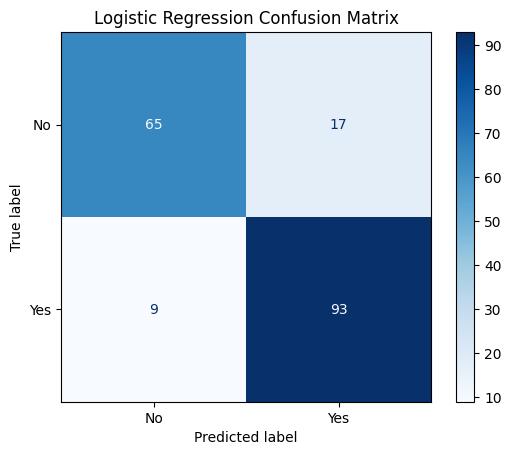

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

##Feature importance

                Feature  Coefficient  Absolute Importance
10             ST slope     1.745140             1.745140
1                   sex     1.237596             1.237596
5   fasting blood sugar     1.157167             1.157167
8       exercise angina     0.950164             0.950164
2       chest pain type     0.700876             0.700876
9               oldpeak     0.212209             0.212209
6           resting ecg     0.097866             0.097866
7        max heart rate    -0.014026             0.014026
0                   age     0.004155             0.004155
4           cholesterol     0.001882             0.001882
3          resting bp s     0.001244             0.001244


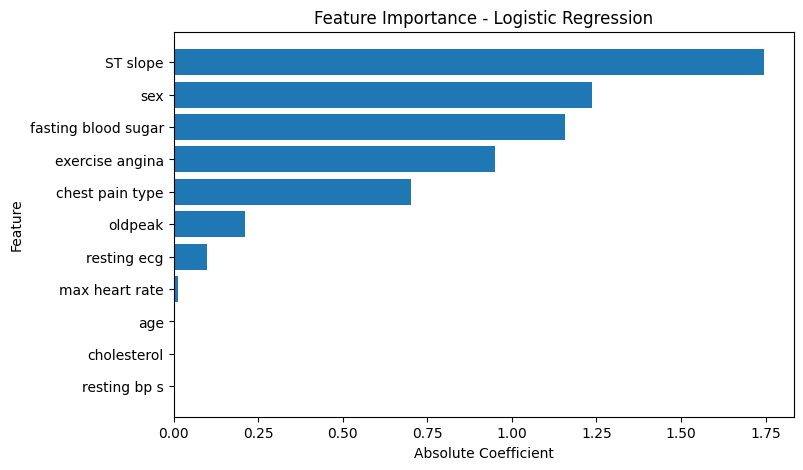

In [ ]:
importance = pd.DataFrame({
    "Feature": x_axis.columns,
    "Coefficient": model.coef_[0],
    "Absolute Importance": abs(model.coef_[0])
})

importance = importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Absolute Importance"])
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance - Logistic Regression")
plt.gca().invert_yaxis()
plt.show()

##Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(x_train, y_train)
rf_predictions = rf_model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Accuracy: 0.8858695652173914

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87        82
           1       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184


Confusion Matrix:
[[70 12]
 [ 9 93]]


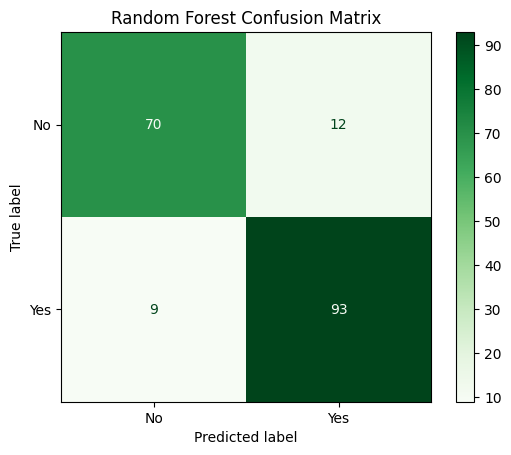

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No", "Yes"],
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

                Feature  Importance
10             ST slope    0.252707
2       chest pain type    0.126446
7        max heart rate    0.118093
9               oldpeak    0.107331
4           cholesterol    0.083786
0                   age    0.082299
8       exercise angina    0.075381
3          resting bp s    0.069070
1                   sex    0.033591
5   fasting blood sugar    0.027650
6           resting ecg    0.023646


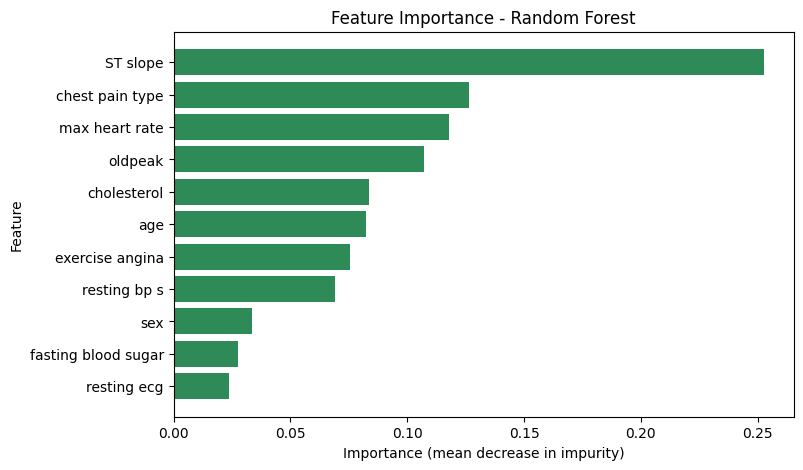

In [ ]:
rf_importance = pd.DataFrame({
    "Feature": x_axis.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(rf_importance)

plt.figure(figsize=(8, 5))
plt.barh(rf_importance["Feature"], rf_importance["Importance"], color="seagreen")
plt.xlabel("Importance (mean decrease in impurity)")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.show()

## Unsupervised Learning

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(x_train, y_train)
xgb_predictions = xgb_model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, xgb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

Accuracy: 0.8695652173913043

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86        82
           1       0.89      0.87      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184


Confusion Matrix:
[[71 11]
 [13 89]]


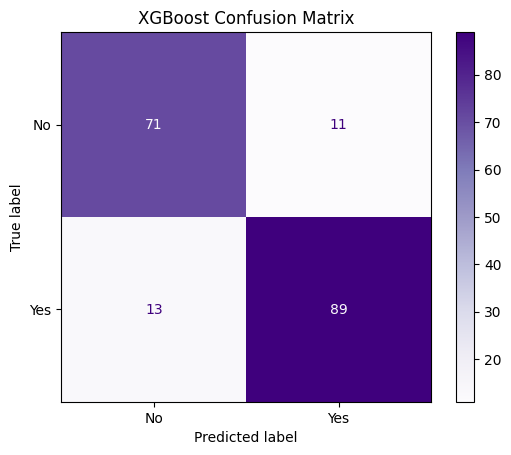

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    display_labels=["No", "Yes"],
    cmap="Purples"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import precision_score, recall_score, f1_score

pca_model = make_pipeline(StandardScaler(), PCA(n_components=1), XGBClassifier(random_state=42))
pca_model.fit(x_train, y_train)

lda_model = make_pipeline(StandardScaler(), LDA(n_components=1), XGBClassifier(random_state=42))
lda_model.fit(x_train, y_train)

variants = {
    "XGBoost": xgb_model,
    "PCA + XGBoost": pca_model,
    "LDA + XGBoost": lda_model,
}

dr_results = pd.DataFrame({
    name: {
        "accuracy":  accuracy_score(y_test, m.predict(x_test)),
        "precision": precision_score(y_test, m.predict(x_test)),
        "recall":    recall_score(y_test, m.predict(x_test)),
        "f1_score":  f1_score(y_test, m.predict(x_test)),
        "roc_auc":   roc_auc_score(y_test, m.predict_proba(x_test)[:, 1]),
    }
    for name, m in variants.items()
}).round(4)

dr_results

,XGBoost,PCA + XGBoost,LDA + XGBoost
accuracy,0.8696,0.8043,0.8261
precision,0.8900,0.8438,0.8182
recall,0.8725,0.7941,0.8824
f1_score,0.8812,0.8182,0.8491
roc_auc,0.9168,0.8880,0.8563


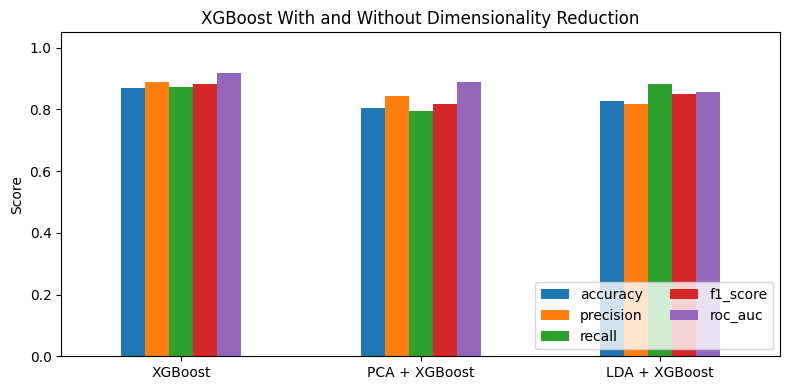

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
dr_results.T.plot(kind="bar", ax=ax, rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("XGBoost With and Without Dimensionality Reduction")
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

##Model Comparison

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
}

rows = []
for name, m in models.items():
    pred = m.predict(x_test)
    prob = m.predict_proba(x_test)[:, 1]   # if a model has no predict_proba, see note below
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, m.predict(x_train)),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Train Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.85,0.859,0.845,0.912,0.877,0.906
Random Forest,1.00,0.886,0.886,0.912,0.899,0.923
XGBoost,1.00,0.870,0.890,0.873,0.881,0.917


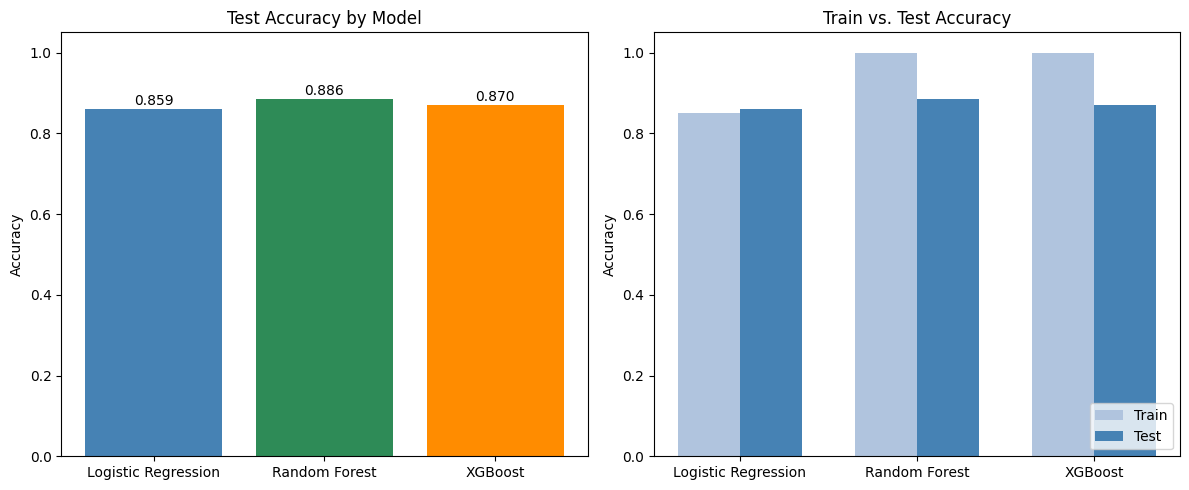

In [ ]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Test accuracy per model
test_acc = results["Test Accuracy"]
bars = axes[0].bar(test_acc.index, test_acc.values, color=["steelblue", "seagreen", "darkorange", "mediumpurple"][:len(test_acc)])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Test Accuracy by Model")
for bar, v in zip(bars, test_acc.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")

# Train vs. test accuracy
x = np.arange(len(results))
width = 0.35
axes[1].bar(x - width / 2, results["Train Accuracy"], width, label="Train", color="lightsteelblue")
axes[1].bar(x + width / 2, results["Test Accuracy"], width, label="Test", color="steelblue")
axes[1].set_xticks(x)
axes[1].set_xticklabels(results.index)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Train vs. Test Accuracy")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

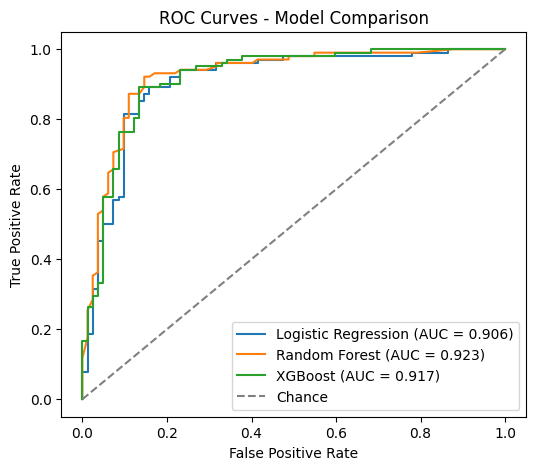

In [ ]:
plt.figure(figsize=(6, 5))

for name, m in models.items():
    prob = m.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend(loc="lower right")
plt.show()